In [280]:
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict,Literal
from typing import Annotated
from langchain_core.messages import BaseMessage, HumanMessage,SystemMessage
from langgraph.checkpoint.memory import InMemorySaver 
from pydantic import BaseModel,Field

In [281]:
class State(TypedDict):
    agent:str
    llm:str
    msg: Annotated[list[BaseMessage],add_messages] 

In [282]:
from langchain_groq import ChatGroq
gpt_oss_120b = ChatGroq(model="openai/gpt-oss-120b")
gpt_oss_20b = ChatGroq(model="openai/gpt-oss-20b")
qwen3_8_27b = ChatGroq(model="qwen/qwen3.8-27b")


In [283]:
print(qwen3_8_27b.profile["name"]
      )


Qwen3.8 27B


In [284]:
graph = StateGraph(State)

In [285]:
def Classify_Query(state: State):
    class Route(BaseModel):
        agent: Literal["technical", "general", "coding"] = Field(
            description="The agent best suited for the query"
        )

        llm: Literal[
            "gpt_oss_120b",
            "gpt_oss_20b",
            "qwen3_8_27b"
        ] = Field(
            description="The best LLM for handling the query"
        )
    messages = [
        SystemMessage(
            content="""
            You are an intelligent query router.

            Select the most suitable agent:

            technical: Computer science, AI, ML, engineering concepts.
            general: General knowledge and normal conversations.
            coding: Programming, debugging, code generation.

            Also select the most suitable LLM:

            gpt_oss_120b: Complex reasoning and difficult technical tasks.
            gpt_oss_20b: Simple queries and lightweight tasks.
            qwen3_8_27b: Coding, programming and code debugging.

            Choose the agent and LLM based on the user's query.
            """
        ),
        state["msg"][-1]
    ]

    structured_llm = gpt_oss_20b.with_structured_output(Route)

    response = structured_llm.invoke(messages)

    return {
        "agent": response.agent,
        "llm": response.llm
    }

In [286]:
def get_llm(state: State):

    models = {
        "gpt_oss_120b": gpt_oss_120b,
        "gpt_oss_20b": gpt_oss_20b,
        "qwen3_8_27b": qwen3_8_27b
    }

    return models[state["llm"]]

In [287]:
def Technical_Agent(state: State):
    llm = get_llm(state)
    print(f"===Selected Tech Agent Using {llm.profile["name"]}===")
    response = llm.invoke([
        SystemMessage(
            content="You are a technical expert. Explain technical concepts clearly."
        ),
        *state["msg"]
    ])

    return {"msg": [response]}

In [288]:
def general_agent(state: State):
    llm = get_llm(state)

    print(f"===Selected general Agent Using {llm.profile["name"]}===")
    response = llm.invoke([
        SystemMessage(
            content="You are a helpful general-purpose assistant."
        ),
        *state["msg"]
    ])

    return {"msg": [response]}

In [289]:
def coding_agent(state: State):
    llm = get_llm(state)

    print(f"===Selected coding Agent Using {llm.profile["name"]}===")
    response = llm.invoke([
        SystemMessage(
            content="You are an expert programming assistant. Help with code and debugging."
        ),
        *state["msg"]
    ])

    return {"msg": [response]}

In [290]:
def routing(state: State):

    return state["agent"]

In [291]:
graph.add_node("Classify Query",Classify_Query)
graph.add_node("Technical Agent",Technical_Agent)
graph.add_node("General Agent",general_agent)
graph.add_node("Coding Agent",coding_agent)

graph.add_edge(START,"Classify Query")
# graph.add_edge("Classify Query","Technical Agent")
# graph.add_edge("Classify Query","General Agent")
# graph.add_edge("Classify Query","Coding Agent")
graph.add_conditional_edges(
    "Classify Query",
    routing,
    {
        "technical": "Technical Agent",
        "general": "General Agent",
        "coding": "Coding Agent"
    }
)
# graph.add_conditional_edges(
#     "Classify Query",
#     routing,
#     ["Technical Agent","General Agent","Coding Agent"]
# )
graph.add_edge("Technical Agent",END)
graph.add_edge("General Agent",END)
graph.add_edge("Coding Agent",END)

In [292]:
workflow = graph.compile(checkpointer=InMemorySaver())

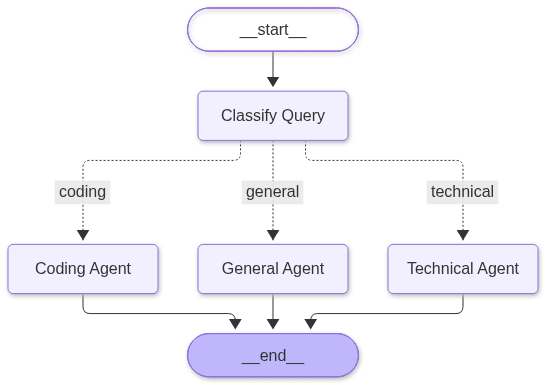

In [293]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [294]:
thread_id  = 1
config = {"configurable":{"thread_id":thread_id}} 
while True:
    inp = input("User: ")
    print("Human: ",inp)
    if inp =="q":break
    response = workflow.invoke({"msg":HumanMessage(content=inp)},config=config)
    print("AI: ", response["msg"][-1].content)


Human:  hii
===Selected general Agent Using GPT OSS 20B===
AI:  Hello! How can I help you today?
Human:  waht can u do
===Selected general Agent Using GPT OSS 20B===
AI:  I’m here to help with a wide range of tasks! Here’s a quick rundown of what I can do:

| Category | What I can help with |
|----------|----------------------|
| **Information & Research** | Quick facts, explanations, summaries, and deeper dives into topics. |
| **Writing & Editing** | Draft emails, essays, reports, creative stories, poems, or help polish existing text. |
| **Coding & Tech** | Explain programming concepts, debug code snippets, write scripts, or help with algorithms. |
| **Math & Science** | Solve equations, explain concepts, walk through proofs, or help with homework. |
| **Language Learning** | Translate, explain grammar, practice conversation, or generate language exercises. |
| **Creative Projects** | Brainstorm ideas, outline plots, design characters, or craft marketing copy. |
| **Planning & Organ

BadRequestError: Error code: 400 - {'error': {'message': 'Tool choice is required, but model did not call a tool', 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': 'You’re welcome! If you have any more questions or need further assistance, just let me know.'}}